# Exercise 2: Finetuning a Pretrained Model for Binary Text Classification

### 1. Cài đặt thư viện (transformers, datasets, evaluate) và kiểm tra GPU
Đã cài trong Terminal: `python -m pip install transformers datasets evaluate accelerate scikit-learn`.

In [1]:
import numpy as np
import torch
import evaluate
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, set_seed)

set_seed(42)
print("GPU:", torch.cuda.is_available(), "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

d:\Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: True - NVIDIA GeForce RTX 3050 6GB Laptop GPU


### 2. Tải bộ dữ liệu phân loại văn bản 2 lớp (rotten_tomatoes)

In [3]:
dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes")
print(dataset)
print("Ví dụ:", dataset["train"][0])
print("Nhãn:", dataset["train"].features["label"].names)

d:\Code\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HUUHAO\.cache\huggingface\hub\datasets--cornell-movie-review-data--rotten_tomatoes. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Code\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-sys

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})
Ví dụ: {'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'label': 1}
Nhãn: ['neg', 'pos']


### 3. Tải model và tokenizer đã huấn luyện sẵn
Cảnh báo *"Some weights ... newly initialized"* là bình thường: lớp phân loại cuối là lớp mới, sẽ được fine-tune.

In [4]:
model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
)

d:\Code\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HUUHAO\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1125.57it/s]
[transformers] DistilBertForSequenceClassification

### 4. Tiền xử lý dữ liệu

In [5]:
def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = dataset.map(tokenize_function, batched=True)

train_ds = tokenized["train"].shuffle(seed=42)   # toàn bộ 8.530 câu
test_ds = tokenized["test"]                      # 1.066 câu

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Train:", len(train_ds), "| Test:", len(test_ds))

Map: 100%|██████████| 1066/1066 [00:00<00:00, 17678.66 examples/s]

Train: 8530 | Test: 1066


### 5. Định nghĩa tham số huấn luyện

In [6]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1.compute(predictions=preds, references=labels)["f1"],
    }

training_args = TrainingArguments(
    output_dir="results_ex2",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=50,
    fp16=torch.cuda.is_available(),   # GPU NVIDIA: dùng 16-bit cho nhanh
    report_to="none",
    seed=42,
)

### 6. Tạo Trainer và fine-tune model

In [7]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

before = trainer.evaluate()
print(f"TRƯỚC fine-tune: accuracy = {before['eval_accuracy']:.2%}")

trainer.train()

Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.697295,0,0.428705,0.141044


TRƯỚC fine-tune: accuracy = 42.87%


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.400191,0.362503,0.844278,0.840077
2,0.229674,0.440827,0.846154,0.843810
3,0.144736,0.546950,0.846154,0.846729


TrainOutput(global_step=1602, training_loss=0.27091782005241005, metrics={'train_runtime': 118.6, 'train_samples_per_second': 215.767, 'train_steps_per_second': 13.508, 'total_flos': 322545179457960.0, 'train_loss': 0.27091782005241005, 'epoch': 3.0})

### 7. Đánh giá model sau khi fine-tune

In [8]:
after = trainer.evaluate()
print(f"TRƯỚC fine-tune: accuracy = {before['eval_accuracy']:.2%}")
print(f"SAU fine-tune:   accuracy = {after['eval_accuracy']:.2%} | F1 = {after['eval_f1']:.2%}")

from transformers import pipeline
clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer)
for s in ["An absolute masterpiece with brilliant acting.",
          "Boring plot and terrible dialogue.",
          "Not bad at all!"]:
    r = clf(s)[0]
    print(f"{r['label']:8s} {r['score']:.2%} | {s}")

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.144736,0.546950,3,0.846154,0.846729


TRƯỚC fine-tune: accuracy = 42.87%
SAU fine-tune:   accuracy = 84.62% | F1 = 84.67%
POSITIVE 99.67% | An absolute masterpiece with brilliant acting.
NEGATIVE 99.46% | Boring plot and terrible dialogue.
POSITIVE 95.90% | Not bad at all!


### Biểu đồ training loss

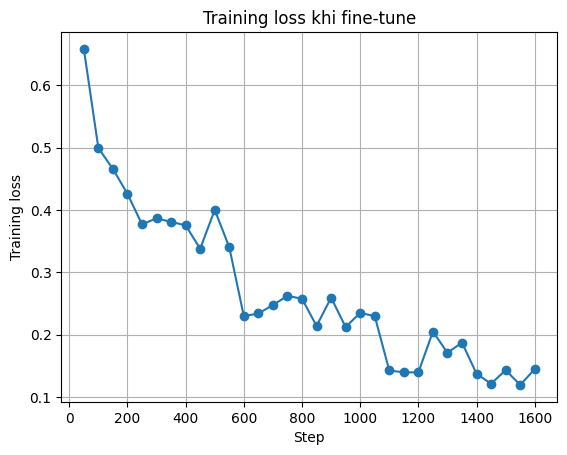

In [9]:
import matplotlib.pyplot as plt
logs = trainer.state.log_history
steps = [l["step"] for l in logs if "loss" in l]
losses = [l["loss"] for l in logs if "loss" in l]
plt.plot(steps, losses, marker="o")
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("Training loss khi fine-tune")
plt.grid(True); plt.show()

### Nhận xét
- **Trước fine-tune:** accuracy chỉ 42.87% (F1 14.10%) vì lớp phân loại cuối của DistilBERT được khởi tạo ngẫu nhiên, model gần như chỉ đoán một nhãn.
- **Sau fine-tune 3 epoch:** accuracy đạt **84.62%**, F1 **84.67%** trên 1.066 câu test, tăng hơn 40 điểm phần trăm. Model dự đoán đúng các câu tự viết, kể cả câu phủ định "Not bad at all!".
- **Biểu đồ loss:** training loss giảm từ khoảng 0.66 xuống khoảng 0.13; các lần giảm mạnh ở khoảng step 534 và 1068 tương ứng với đầu epoch 2 và 3 (8.530 câu / batch 16 ≈ 534 step mỗi epoch).
- **Overfitting:** validation loss thấp nhất ở epoch 1 (0.3625) rồi tăng dần (0.4408 → 0.5470) trong khi training loss vẫn giảm và accuracy gần như không đổi (84.43% → 84.62%). Model bắt đầu học thuộc dữ liệu train; với bộ dữ liệu này 1–2 epoch là đủ.
- **Hướng cải thiện:** dùng early stopping, giảm số epoch, hoặc thử model lớn hơn (BERT-base, RoBERTa).